In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from prophet import Prophet
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import mlflow
import mlflow.sklearn

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

df_raw = pd.read_csv('data/household_power_consumption.txt', sep=';', low_memory=False)
df_raw = df_raw.replace('?', np.nan)
df_raw = df_raw.dropna(subset=['Global_active_power'])
df_raw['Global_active_power'] = df_raw['Global_active_power'].astype(float)
df_raw['Datetime'] = pd.to_datetime(df_raw['Date'] + ' ' + df_raw['Time'], format='%d/%m/%Y %H:%M:%S')
df_raw = df_raw.drop(columns=['Date', 'Time'])
df_raw = df_raw.set_index('Datetime')

df_daily = df_raw['Global_active_power'].resample('D').mean().reset_index()
df_daily.columns = ['ds', 'y']


df_daily['y'] = df_daily['y'].interpolate(method='linear')
df_daily = df_daily.dropna()

print(f"Dataset final : {len(df_daily)} jours, de {df_daily['ds'].min()} à {df_daily['ds'].max()}")
print(f"Valeurs NaN restantes : {df_daily['y'].isnull().sum()}")

Dataset final : 1442 jours, de 2006-12-16 00:00:00 à 2010-11-26 00:00:00
Valeurs NaN restantes : 0


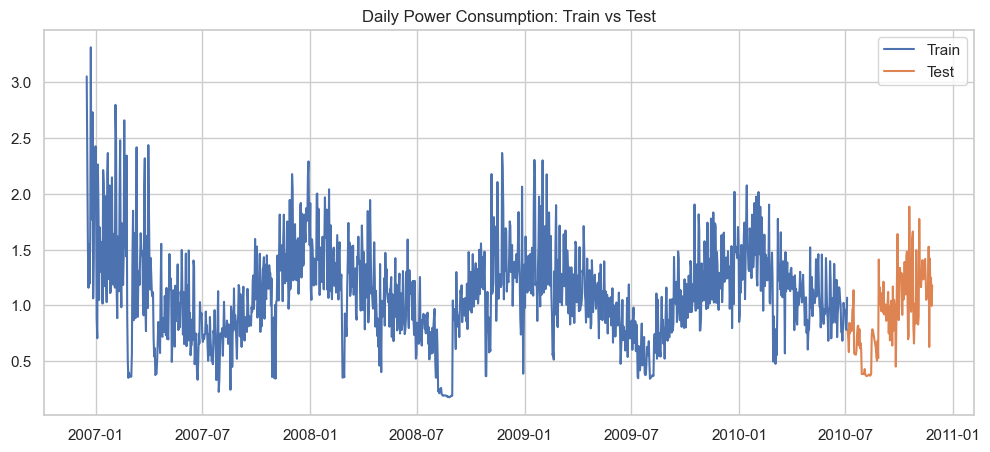

In [14]:
train_size = int(len(df_daily) * 0.9)
train = df_daily.iloc[:train_size]
test = df_daily.iloc[train_size:]

plt.figure(figsize=(12, 5))
plt.plot(train['ds'], train['y'], label='Train')
plt.plot(test['ds'], test['y'], label='Test')
plt.legend()
plt.title('Daily Power Consumption: Train vs Test')
plt.show()

In [15]:
naive_pred = np.full(len(test), train['y'].iloc[-1])
mae_naive = mean_absolute_error(test['y'], naive_pred)
rmse_naive = np.sqrt(mean_squared_error(test['y'], naive_pred))
mape_naive = mean_absolute_percentage_error(test['y'], naive_pred) * 100

In [16]:
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train['y'], order=(1, 1, 1))
fit_arima = model_arima.fit()
pred_arima = fit_arima.forecast(steps=len(test))

mae_arima = mean_absolute_error(test['y'], pred_arima)
rmse_arima = np.sqrt(mean_squared_error(test['y'], pred_arima))
mape_arima = mean_absolute_percentage_error(test['y'], pred_arima) * 100

print(f"ARIMA - MAE: {mae_arima:.4f} | RMSE: {rmse_arima:.4f} | MAPE: {mape_arima:.2f}%")

ARIMA - MAE: 0.2781 | RMSE: 0.3399 | MAPE: 39.55%


In [17]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model_hw = ExponentialSmoothing(
    train['y'], 
    trend='add', 
    seasonal='add', 
    seasonal_periods=7
)
fit_hw = model_hw.fit()
pred_prophet = fit_hw.forecast(steps=len(test))

mae_prophet = mean_absolute_error(test['y'], pred_prophet)
rmse_prophet = np.sqrt(mean_squared_error(test['y'], pred_prophet))
mape_prophet = mean_absolute_percentage_error(test['y'], pred_prophet) * 100

print(f"Holt-Winters - MAE: {mae_prophet:.4f} | RMSE: {rmse_prophet:.4f} | MAPE: {mape_prophet:.2f}%")

Holt-Winters - MAE: 0.3213 | RMSE: 0.3860 | MAPE: 40.37%


In [18]:
def create_lag_features(data, lags=[1, 2, 3, 7]):
    df = data.copy()
    for lag in lags:
        df[f'lag_{lag}'] = df['y'].shift(lag)
    df['rolling_mean_7'] = df['y'].shift(1).rolling(window=7).mean()
    df = df.dropna()
    return df

train_xgb = create_lag_features(train)
test_xgb = create_lag_features(pd.concat([train, test]))

X_train = train_xgb.drop(columns=['ds', 'y'])
y_train = train_xgb['y']
X_test = test_xgb.iloc[-len(test):].drop(columns=['ds', 'y'])
y_test = test_xgb.iloc[-len(test):]['y']

xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, pred_xgb))
mape_xgb = mean_absolute_percentage_error(y_test, pred_xgb) * 100

In [19]:
results = pd.DataFrame({
    'Model': ['Naive', 'ARIMA', 'Prophet', 'XGBoost'],
    'MAE': [mae_naive, mae_arima, mae_prophet, mae_xgb],
    'RMSE': [rmse_naive, rmse_arima, rmse_prophet, rmse_xgb],
    'MAPE (%)': [mape_naive, mape_arima, mape_prophet, mape_xgb]
}).round(4)

print(results.sort_values(by='MAPE (%)'))

     Model     MAE    RMSE  MAPE (%)
3  XGBoost  0.1915  0.2591   22.5019
1    ARIMA  0.2781  0.3399   39.5515
2  Prophet  0.3213  0.3860   40.3718
0    Naive  0.3012  0.3697   47.8612


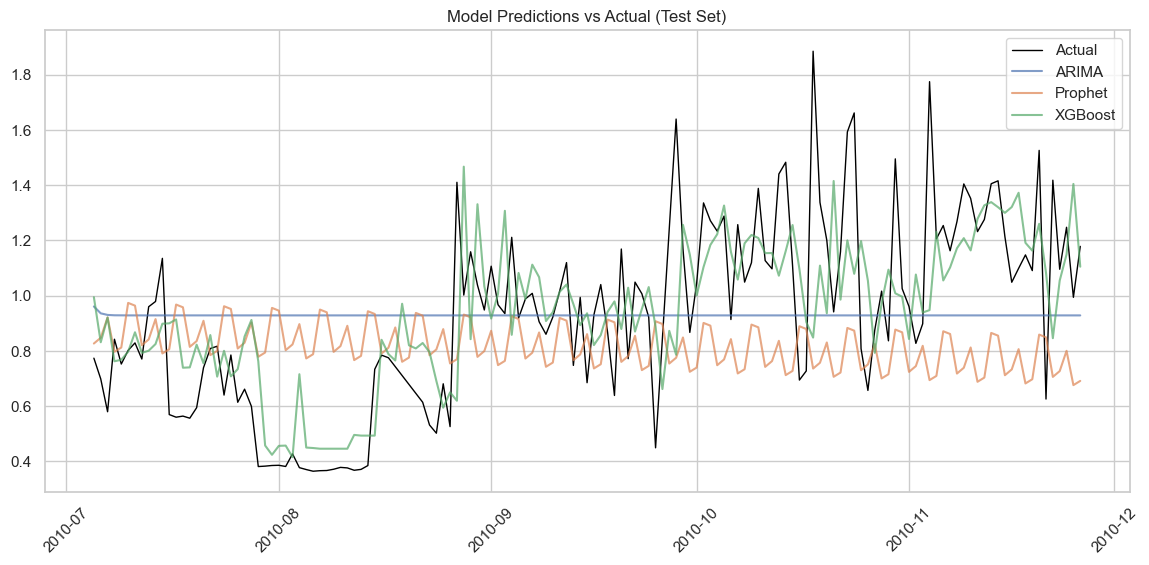

In [20]:
plt.figure(figsize=(14, 6))
plt.plot(test['ds'], test['y'], label='Actual', color='black', linewidth=1)
plt.plot(test['ds'], pred_arima, label='ARIMA', alpha=0.7)
plt.plot(test['ds'], pred_prophet, label='Prophet', alpha=0.7)
plt.plot(test['ds'], pred_xgb, label='XGBoost', alpha=0.7)
plt.legend()
plt.title('Model Predictions vs Actual (Test Set)')
plt.xticks(rotation=45)
plt.show()

Nombre d'anomalies détectées: 0


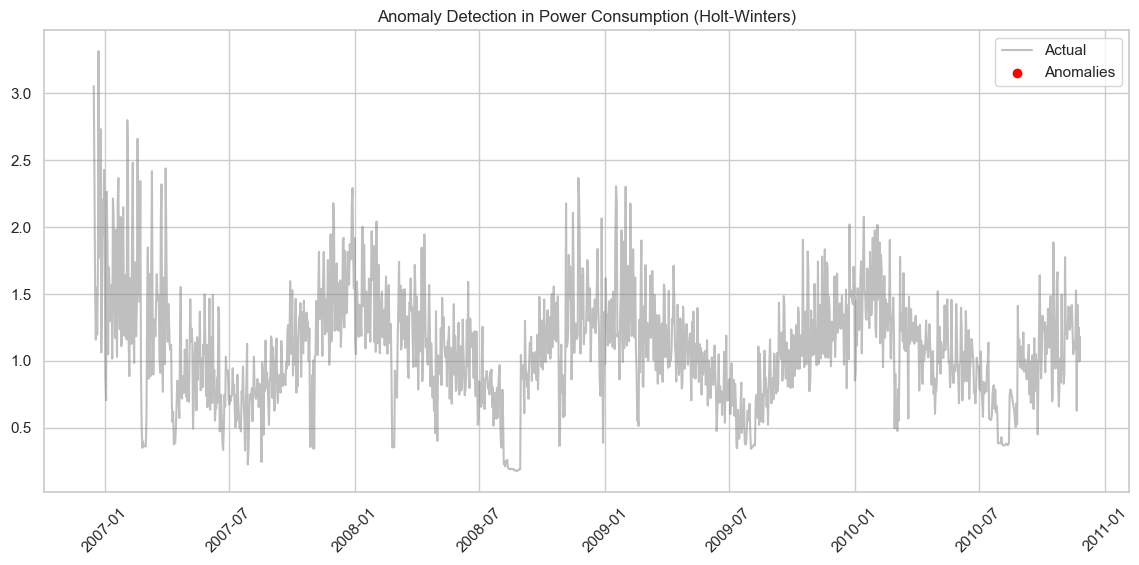

In [21]:
model_hw_full = ExponentialSmoothing(
    df_daily['y'], 
    trend='add', 
    seasonal='add', 
    seasonal_periods=7
)
fit_hw_full = model_hw_full.fit()
forecast_full = fit_hw_full.fittedvalues.copy()
forecast_full.index = df_daily['ds']

residuals = df_daily['y'] - forecast_full
threshold = 3 * residuals.std()
is_anomaly = residuals.abs() > threshold

anomalies = df_daily[is_anomaly]
print(f"Nombre d'anomalies détectées: {len(anomalies)}")

plt.figure(figsize=(14, 6))
plt.plot(df_daily['ds'], df_daily['y'], label='Actual', color='gray', alpha=0.5)
plt.scatter(anomalies['ds'], anomalies['y'], color='red', label='Anomalies', zorder=5)
plt.title('Anomaly Detection in Power Consumption (Holt-Winters)')
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [22]:
mlflow.set_experiment("Time_Series_Forecasting_Olist")

with mlflow.start_run(run_name="XGBoost_Model"):
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_metric("MAE", mae_xgb)
    mlflow.log_metric("RMSE", rmse_xgb)
    mlflow.log_metric("MAPE", mape_xgb)
    mlflow.sklearn.log_model(xgb_model, "xgboost_model")
    print("MLflow run logged successfully.")

MLflow run logged successfully.
